In [ ]:
# Purpose:
#   Validate and contextualize the NHB-BC Up signature in external cohorts by
#   comparing it with intrinsic immune programs (G1–G5) using GSVA scores, and
#   assess their relationships via clustering, correlation heatmaps, and
#   signature–signature scatter correlations.
#
# Steps:
#   1) Load GSVA/ssGSEA scores (G1–G5 + NHB-BC Up) for external datasets (23pt, 160pt).
#   2) Z-score all signature scores across samples for comparability.
#   3) Plot hierarchical clustermaps (correlation distance) of signatures.
#   4) Compute and visualize Spearman correlation matrices among signatures.
#   5) For each dataset, generate faceted scatter plots:
#        - x-axis: G1–G5 program scores
#        - y-axis: NHB-BC Up score
#        - annotate Spearman ρ and p-value.
#   6) Save publication-ready SVG figures for heatmaps, corrmaps, and scatters.

# Header

In [1]:
from utils import *

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [3]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]

In [4]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}


In [5]:
os.chdir('../')

# Breast cancer cohort (n=23)

In [37]:
mg = pd.read_csv('data/09_externalds/23pt_clean/gsva_23pt_NhbBcSigUp.csv', 
              index_col=0)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB-BC Up All,NHB-BC Up Protein
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.662794,7.487532,5.098206,5.327076
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.583236,4.060746,4.648828,5.021416
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.770192,2.129005,4.622036,5.016191
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.982825,3.310755,4.632169,5.007393
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.098141,3.022511,4.464692,4.954098
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.933928,5.688330,4.742468,5.106630
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.191458,2.409984,4.575156,4.881870
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.007700,3.810841,4.647170,5.037369
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.755667,2.378611,4.609838,4.872564
SRX8136168,SRX8136168,GSE148892,Whole_blood,GSM4485284,2.606932,1.817798,7.692762,6.567656,5.289806,5.037537,5.347959


In [38]:
mg.loc[:,'NHB-BC'] = mg.loc[:,'NHB-BC Up All']

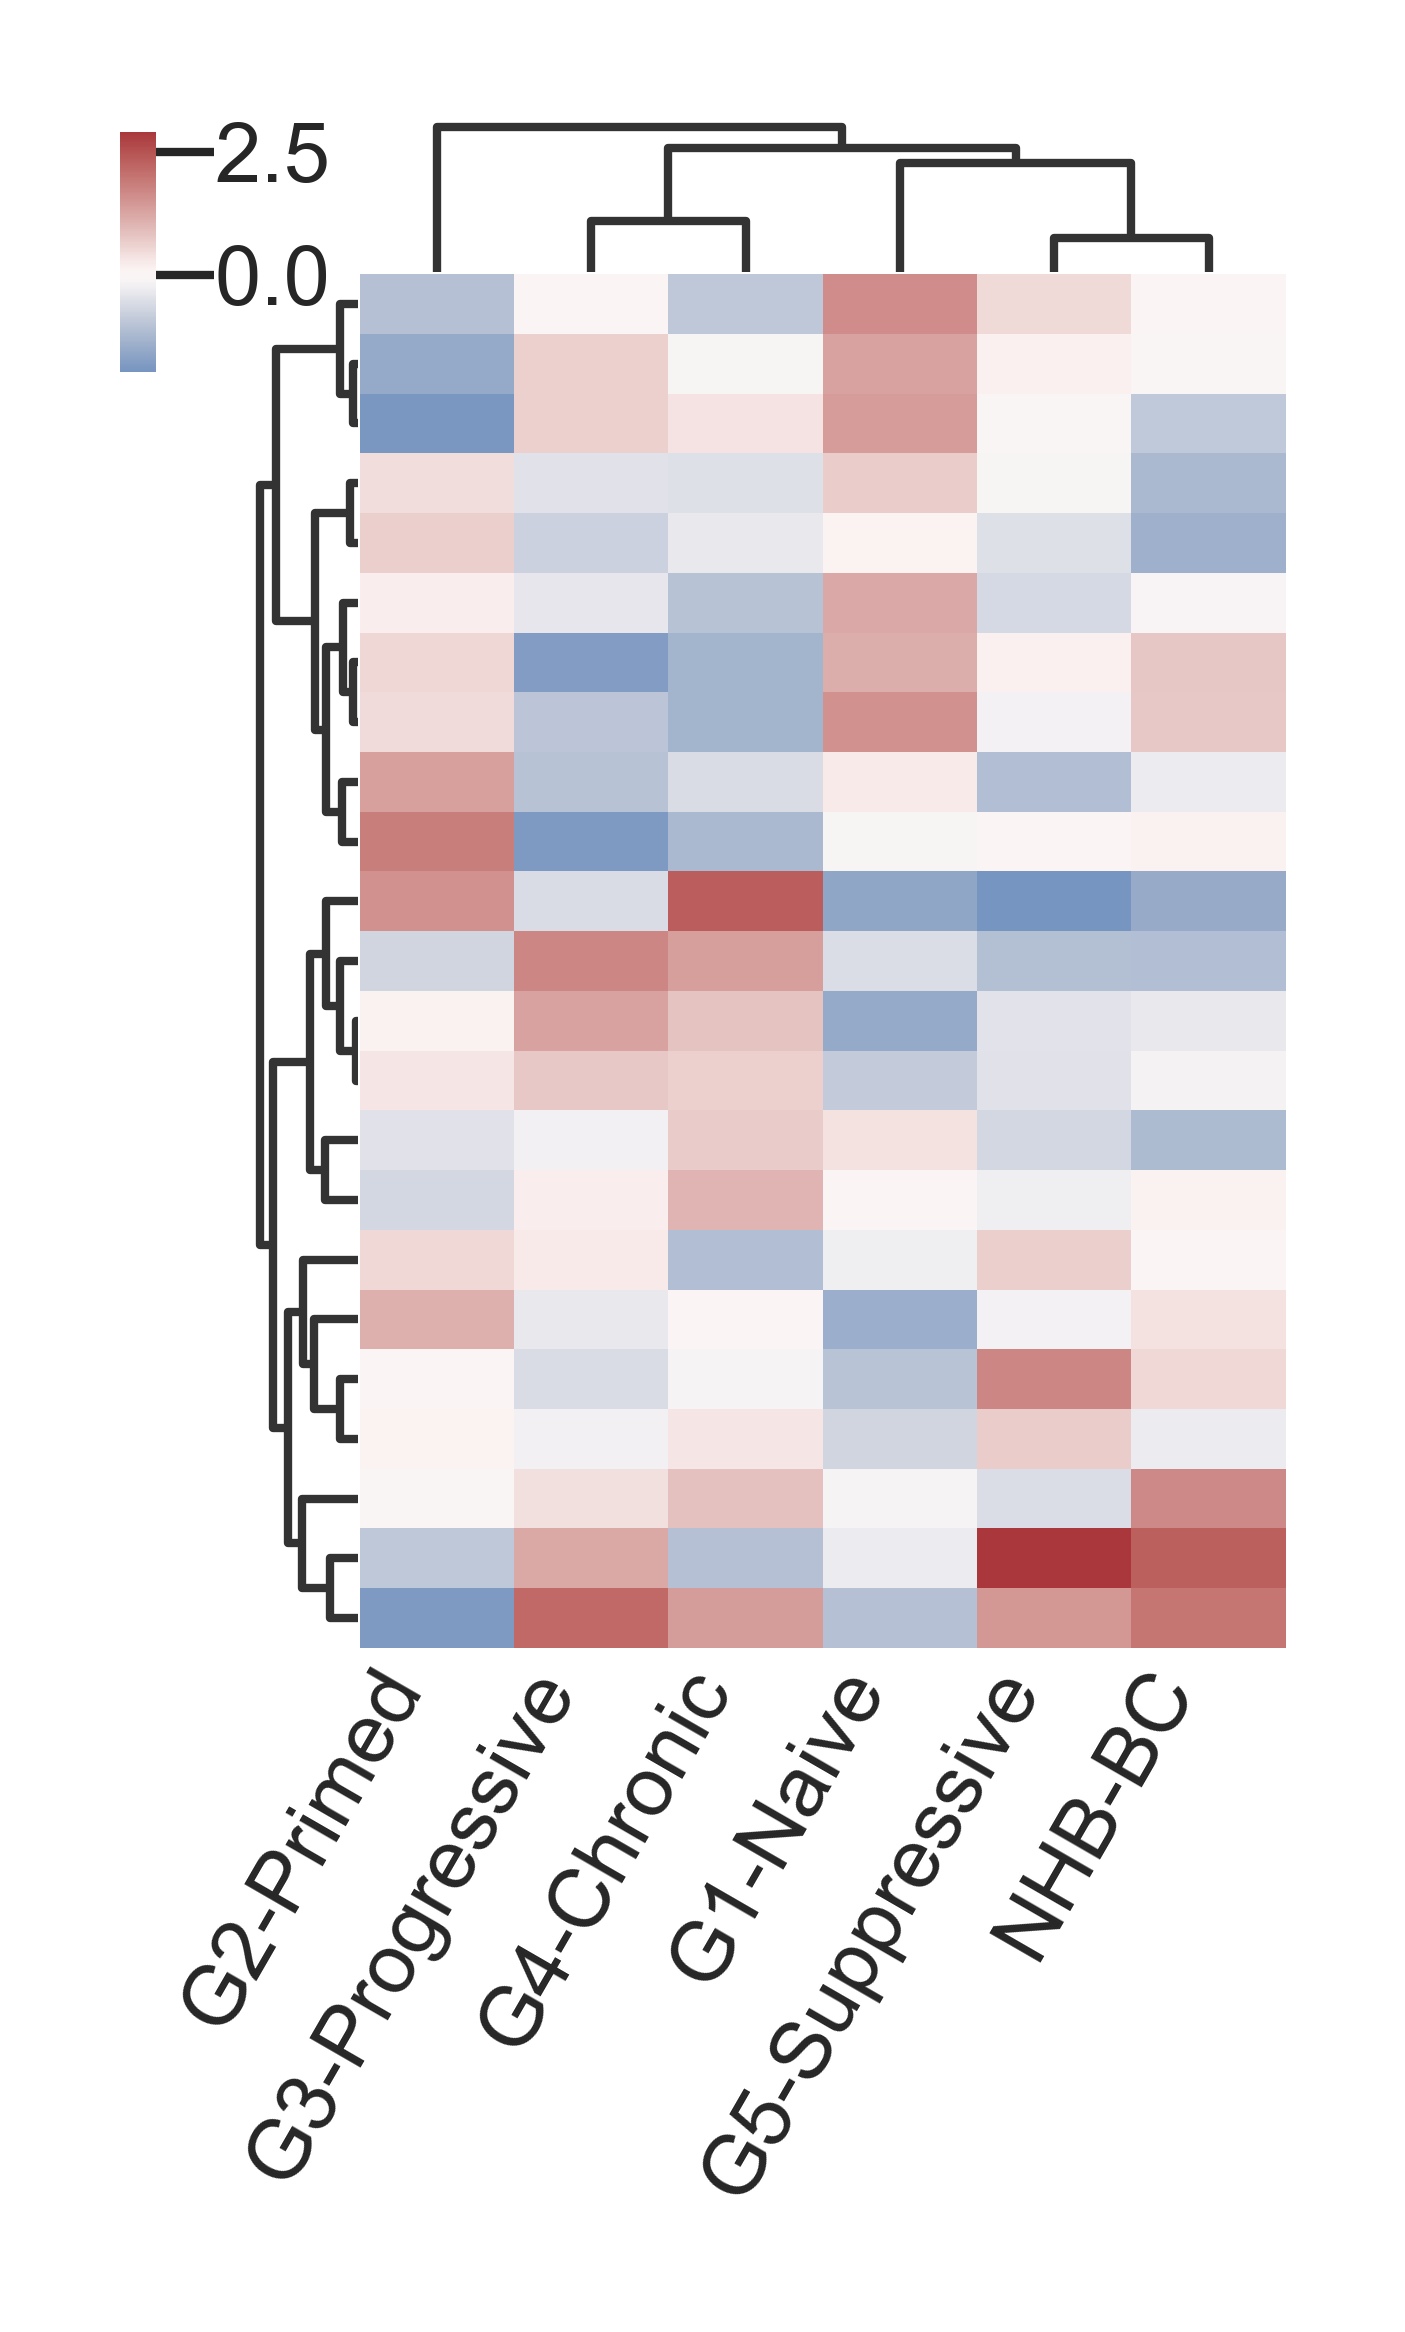

In [39]:
from scipy.stats import zscore
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# === 1. Prepare data ===
cols_sel = [
    'G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
    'NHB-BC'# All','NHB-BC Up Protein'
]

mat = mg[cols_sel].apply(pd.to_numeric, errors='coerce')

# Z-score columns
mat_scaled = pd.DataFrame(
    zscore(mat.values, axis=0, nan_policy='omit'),
    index=mat.index,
    columns=mat.columns
)

# === 2. Custom x-axis labels ===
xtick_map = {
    'G1_signature': 'G1-Naive',
    'G2_signature': 'G2-Primed',
    'G3_signature': 'G3-Progressive',
    'G4_signature': 'G4-Chronic',
    'G5_signature': 'G5-Suppressive',
    'NHB-BC': 'NHB-BC'
    # 'NHB-BC Up All': 'NHB-BC Up All',
    # 'NHB-BC Up Protein': 'NHB-BC Up Protein'
}
mat_scaled.columns = [xtick_map.get(c, c) for c in mat_scaled.columns]

# === 3. Plot clustermap ===
g = sns.clustermap(
    mat_scaled,
    metric='correlation',
    method='average',
    cmap='vlag', center=0,
    figsize=(1.5, 2),
    dendrogram_ratio=.1,
    cbar_pos=(-.015, .85, 0.02, 0.1)  # (x, y, width, height) — lower left, thinner, shorter
)

# Remove y-axis tick labels
g.ax_heatmap.set_yticklabels([])

# Rotate x-axis labels for clarity
g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(),
    rotation=60, ha='right', fontsize=5
)

g.ax_heatmap.tick_params(axis='y', length=0)
g.ax_heatmap.tick_params(axis='x', pad=-3)

# plt.savefig('plots/F8/23pt_heatmap.svg', bbox_inches='tight')

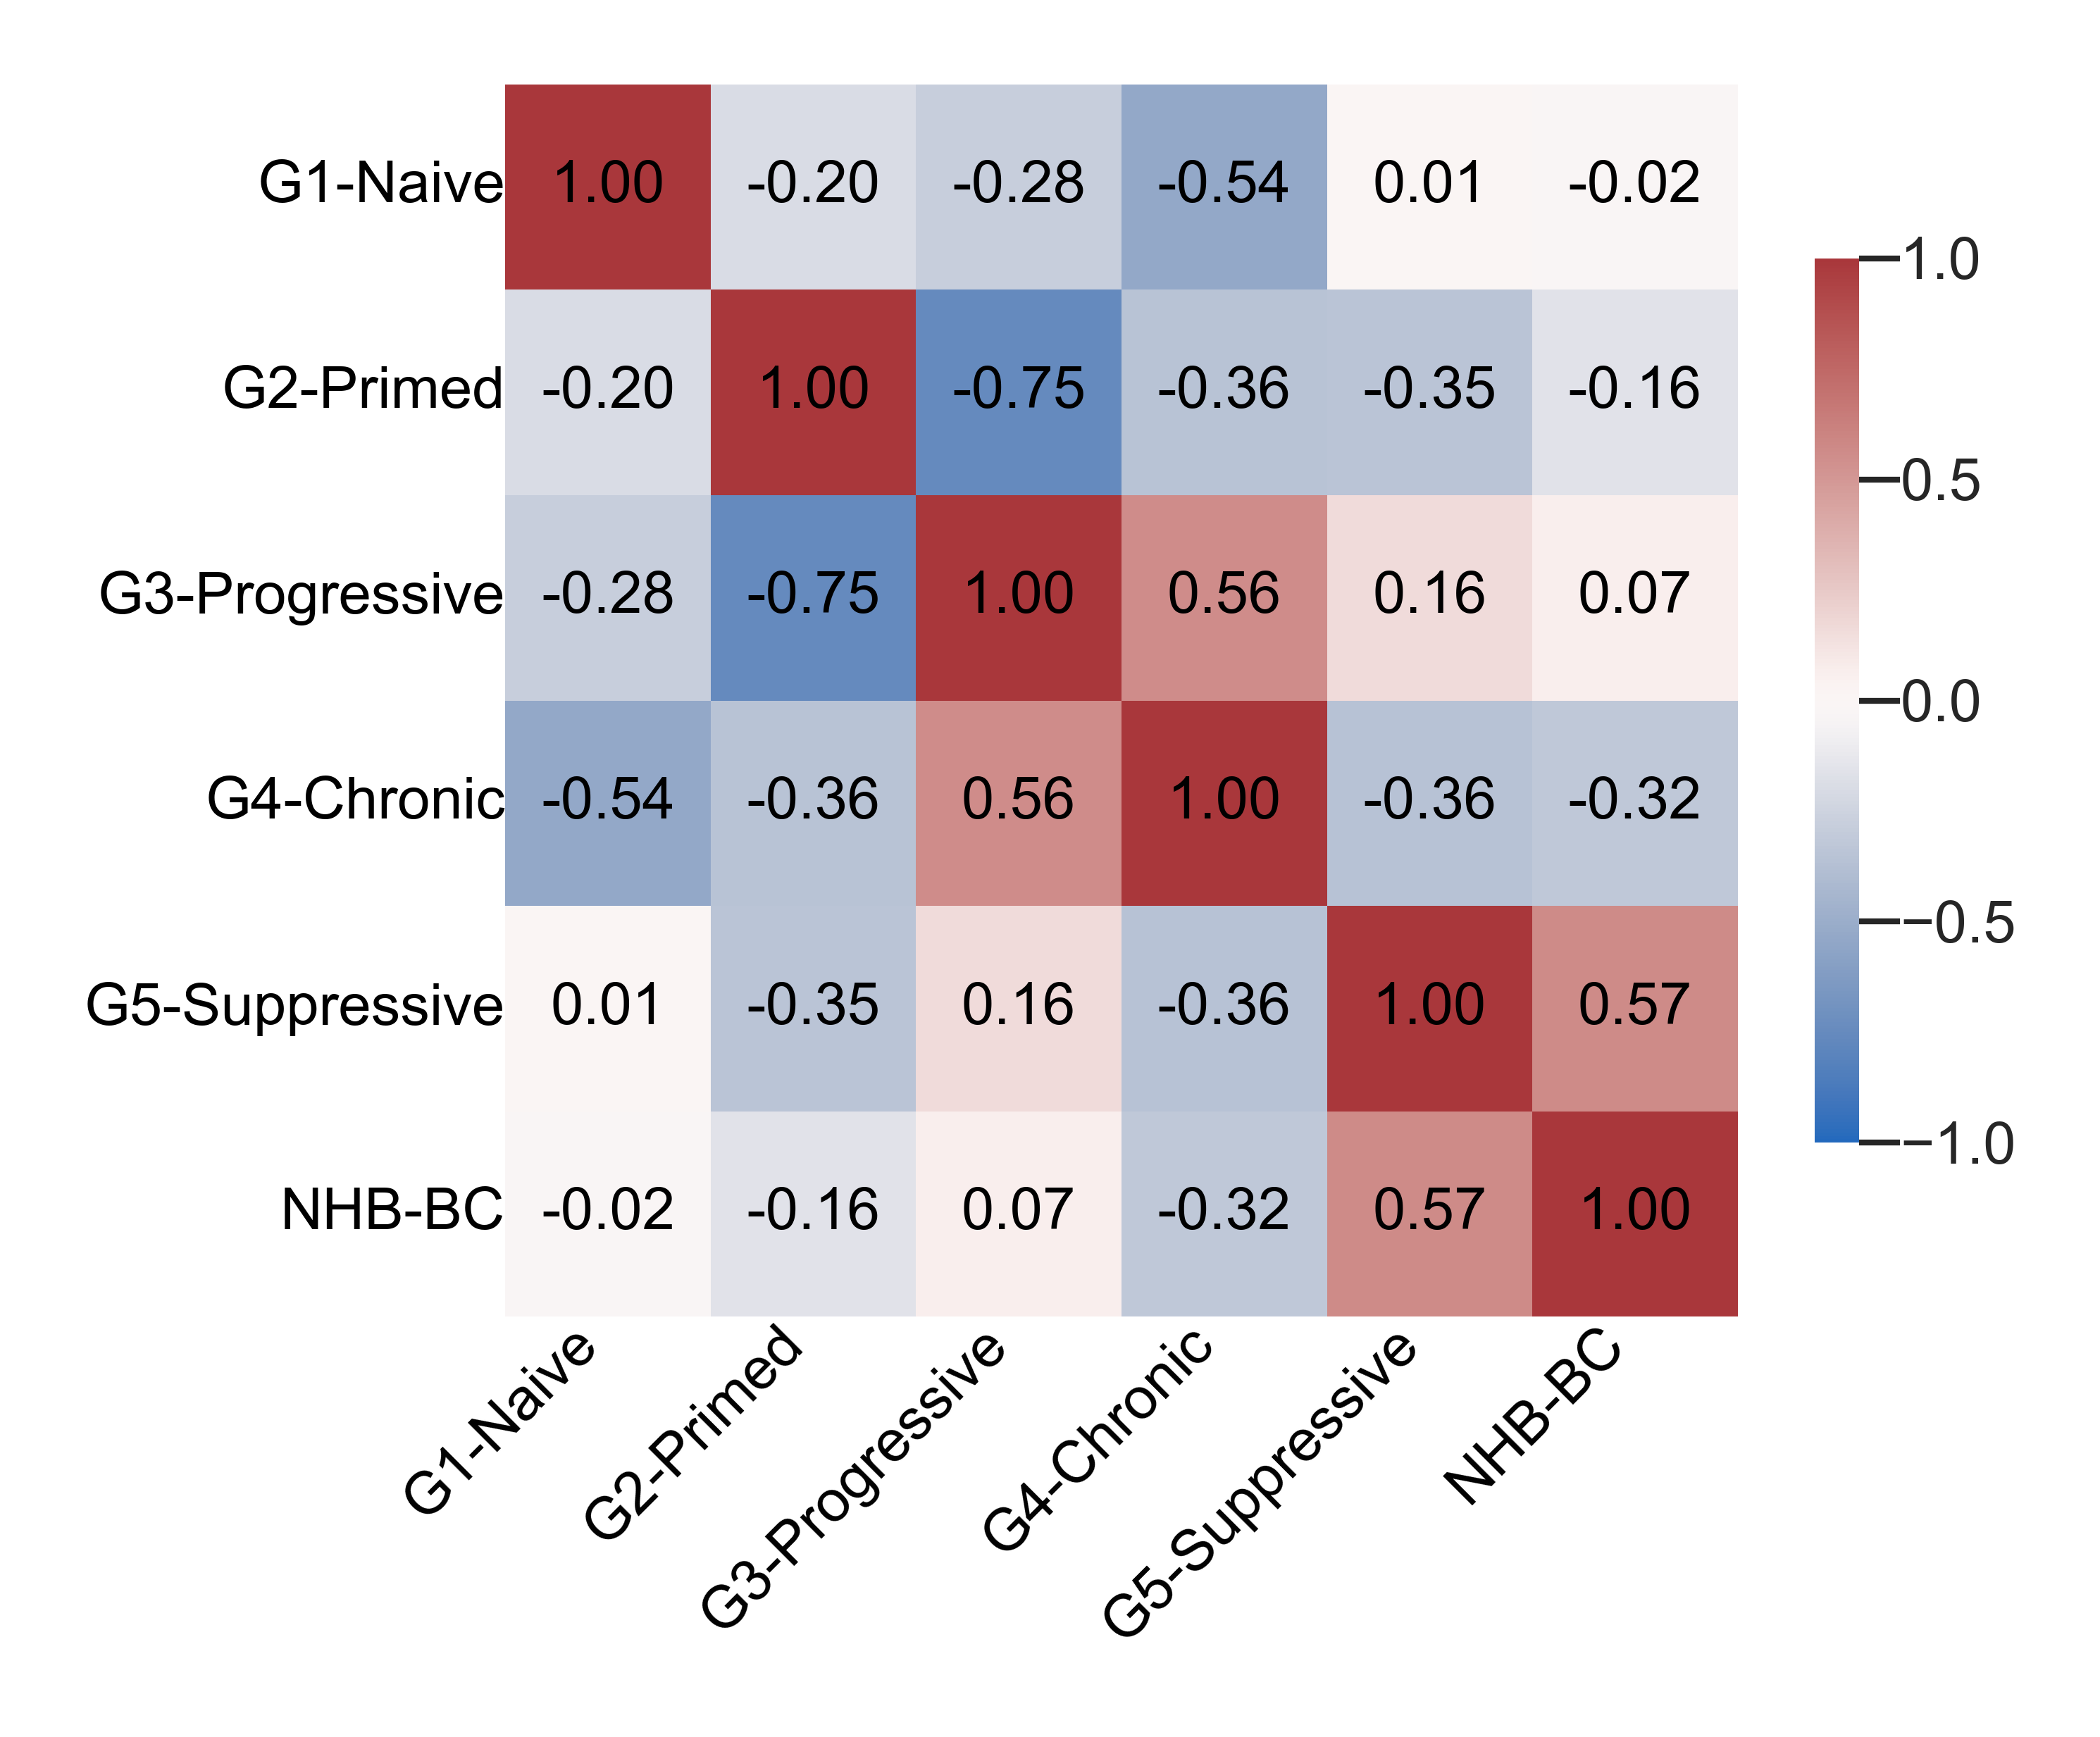

In [40]:
cor_mat = mat_scaled.corr(method='spearman')

# Mask the lower triangle (show upper only)
mask = np.tril(np.ones_like(cor_mat, dtype=bool), k=-1)

plt.figure(figsize=(2.5, 2.5))
ax = sns.heatmap(
    cor_mat,
    mask=None,
    cmap='vlag',      # reversed: blue=high, red=low/negative
    vmin=-1, vmax=1,
    annot=True,         # add coefficients
    fmt=".2f",
    annot_kws={"color": "black", "fontsize": 5},
    square=True,
    cbar_kws={"shrink": 0.5}
)

# Ticks in black (like tl.col='black')
ax.tick_params(colors='black', labelsize=5, length=0, pad=0)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)


plt.tight_layout()
plt.savefig('plots/F8/23pt_corrmap.svg', bbox_inches='tight')

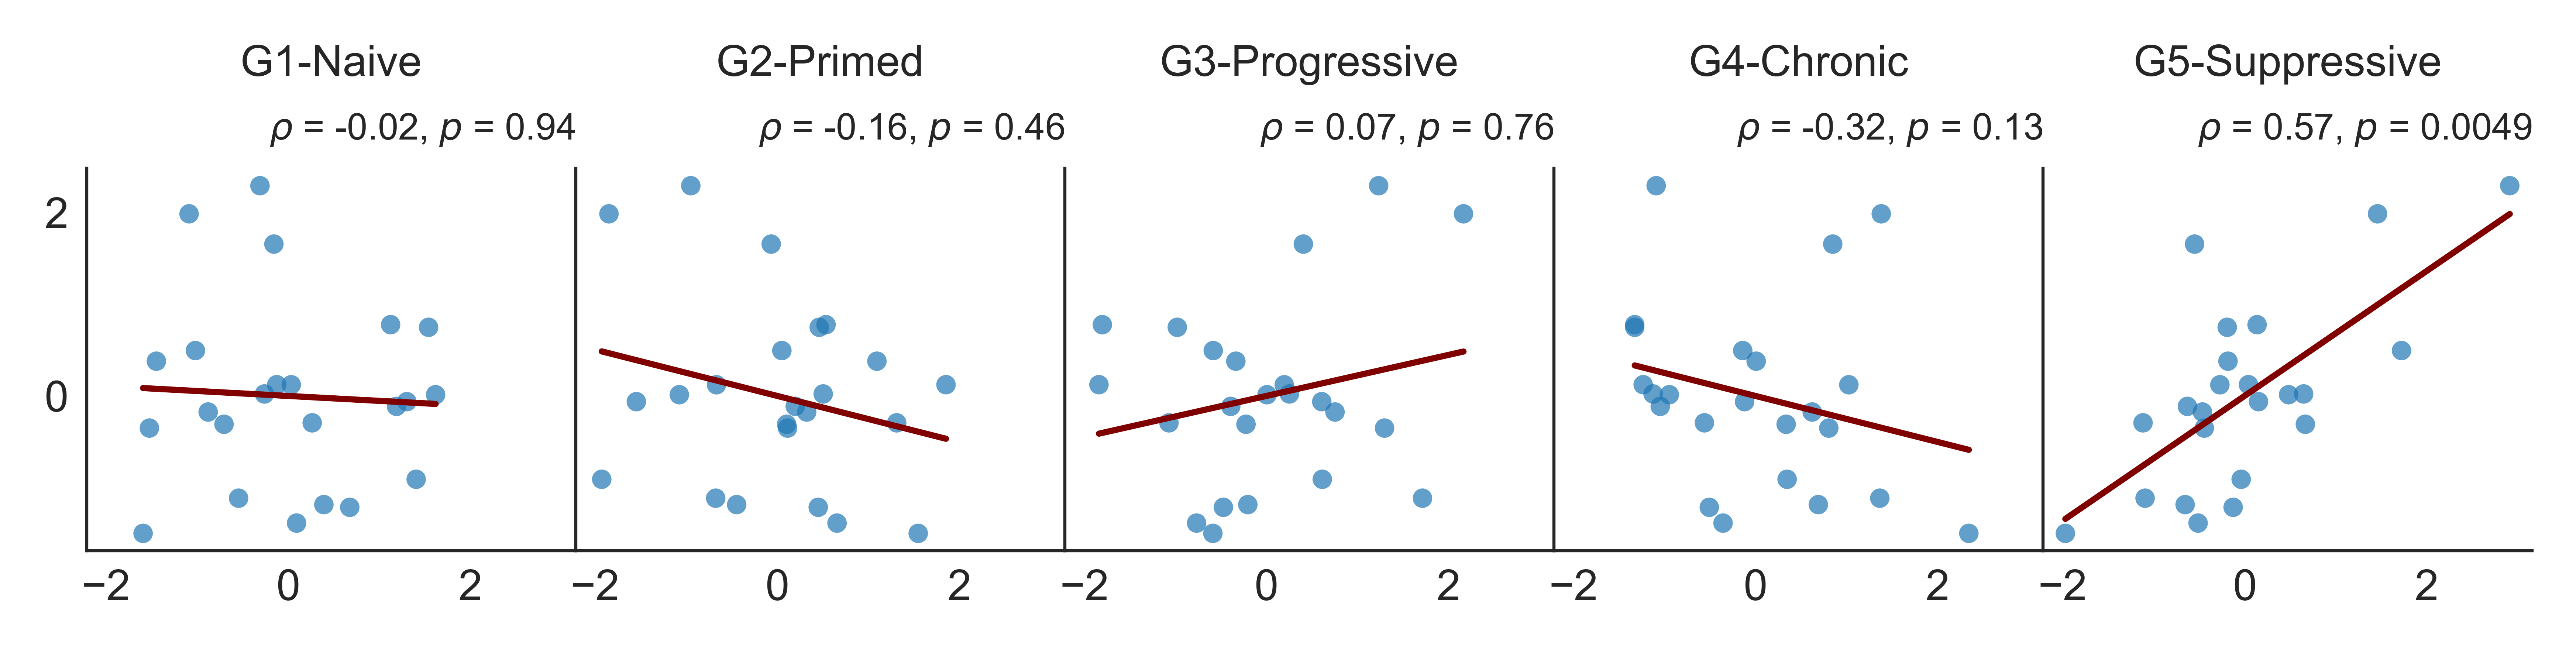

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import spearmanr

sns.set_style("white")

sig_map = {
    'G1_signature': 'G1-Naive',
    'G2_signature': 'G2-Primed',
    'G3_signature': 'G3-Progressive',
    'G4_signature': 'G4-Chronic',
    'G5_signature': 'G5-Suppressive'
}
score_names = list(sig_map.values())

# Prepare long format
df_scores = (
    mat_scaled.reset_index(drop=True)[score_names]
    .rename(columns=sig_map)
    .assign(idx=lambda d: d.index)
    .melt(id_vars='idx', var_name='Signature', value_name='Score')
)

df_outcomes = (
    mat_scaled.reset_index(drop=True)[['NHB-BC']]
    .assign(idx=lambda d: d.index)
    .melt(id_vars='idx', var_name='OutcomeName', value_name='OutcomeValue')
)

df_long = df_scores.merge(df_outcomes, on='idx').drop(columns='idx')

# Function to map scatter + regression + annotation
def facet_scatter(data, color, **kws):
    ax = plt.gca()
    ax.scatter(data["Score"], data["OutcomeValue"], s=10, alpha=0.7, edgecolor="none")
    sns.regplot(
        data=data, x="Score", y="OutcomeValue",
        scatter=False, ci=None, ax=ax, color='maroon', line_kws={"lw": 1.0}
    )
    x = data["Score"].to_numpy()
    y = data["OutcomeValue"].to_numpy()
    if np.nanstd(x) > 0 and np.nanstd(y) > 0:
        r, p = spearmanr(x, y, nan_policy='omit')
        txt = f"$\\rho$ = {r:.2f}, $p$ = {p:.2g}"
    else:
        txt = r"$\rho$ = NA\n$p$ = NA"

    ax.text(
        1, 1.1, txt,          # middle-right
        transform=ax.transAxes,
        ha="right", va="center",
        fontsize=6
    )
    
# Split by OutcomeName and plot/save each row
for outcome_name in df_long["OutcomeName"].unique():
    df_row = df_long[df_long["OutcomeName"] == outcome_name]

    g = sns.FacetGrid(
        df_row,
        col="Signature",
        sharex=True, sharey=True,
        height=1, aspect=1.0
    )
    g.map_dataframe(facet_scatter)

    # Make panels square
    for ax, sig in zip(g.axes.flat, score_names):
        ax.set_ylabel('', fontsize=7)
        ax.set_title(sig, fontsize=7, pad=15)
        ax.set_xlabel('', fontsize=6)
        ax.tick_params(labelsize=7, length=2, pad=1)

    
    # Save as SVG
    fname = f"plots/F8/23pt_scatter_{outcome_name.replace(' ', '_')}.svg"
    g.fig.set_size_inches(6, 2)

    g.fig.subplots_adjust(wspace=0.0005, hspace=0.02)
    
    g.savefig(fname, bbox_inches='tight')
    plt.show()

# Pan cancer cohort (n=160)

In [56]:
mg = pd.read_csv('data/09_externalds/18k_clean/gsva_160pt_NhbBcSigUp.csv', 
              index_col=0)
mg

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB-BC Up All,NHB-BC Up Protein
SRX3146378,SRX3146378,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760044,5.707469,1.934101,9.561733,5.232093,0.882671,1.303932,1.289707
SRX3146379,SRX3146379,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760045,6.040090,2.707472,4.838370,6.676785,1.836293,1.242735,1.267896
SRX3146380,SRX3146380,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760046,5.281971,5.016304,5.908280,3.529771,1.140381,1.158764,1.193764
SRX3146381,SRX3146381,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760047,3.518146,2.653013,6.720693,5.487212,4.383409,1.398004,1.406508
SRX3146382,SRX3146382,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760048,4.987088,6.501059,2.738035,2.214857,2.795963,1.023672,1.010693
...,...,...,...,...,...,...,...,...,...,...,...,...
SRX9031293,SRX9031293,GSE157086,Hepatoma,Whole_blood,GSM4752727,5.485784,1.456098,7.776443,4.317238,2.308074,1.501561,1.512405
SRX9031294,SRX9031294,GSE157086,Hepatoma,Whole_blood,GSM4752728,6.565000,2.813327,3.774976,2.950467,4.362024,1.463487,1.497466
SRX9031295,SRX9031295,GSE157086,Esophageal_Squamous_Cell_Carcinoma,Whole_blood,GSM4752729,2.472520,5.676900,4.037432,5.942094,2.969511,1.493094,1.527464
SRX9031296,SRX9031296,GSE157086,Esophageal_Squamous_Cell_Carcinoma,Whole_blood,GSM4752730,3.129390,5.821677,3.670283,4.943671,3.016333,1.493708,1.526288


In [57]:
mg.loc[:,'NHB-BC'] = mg.loc[:,'NHB-BC Up All']
# see 13.2, Thus here results using the 2 genesets are the same (because the expression matrix gene list were shrink by merging so many datasets)

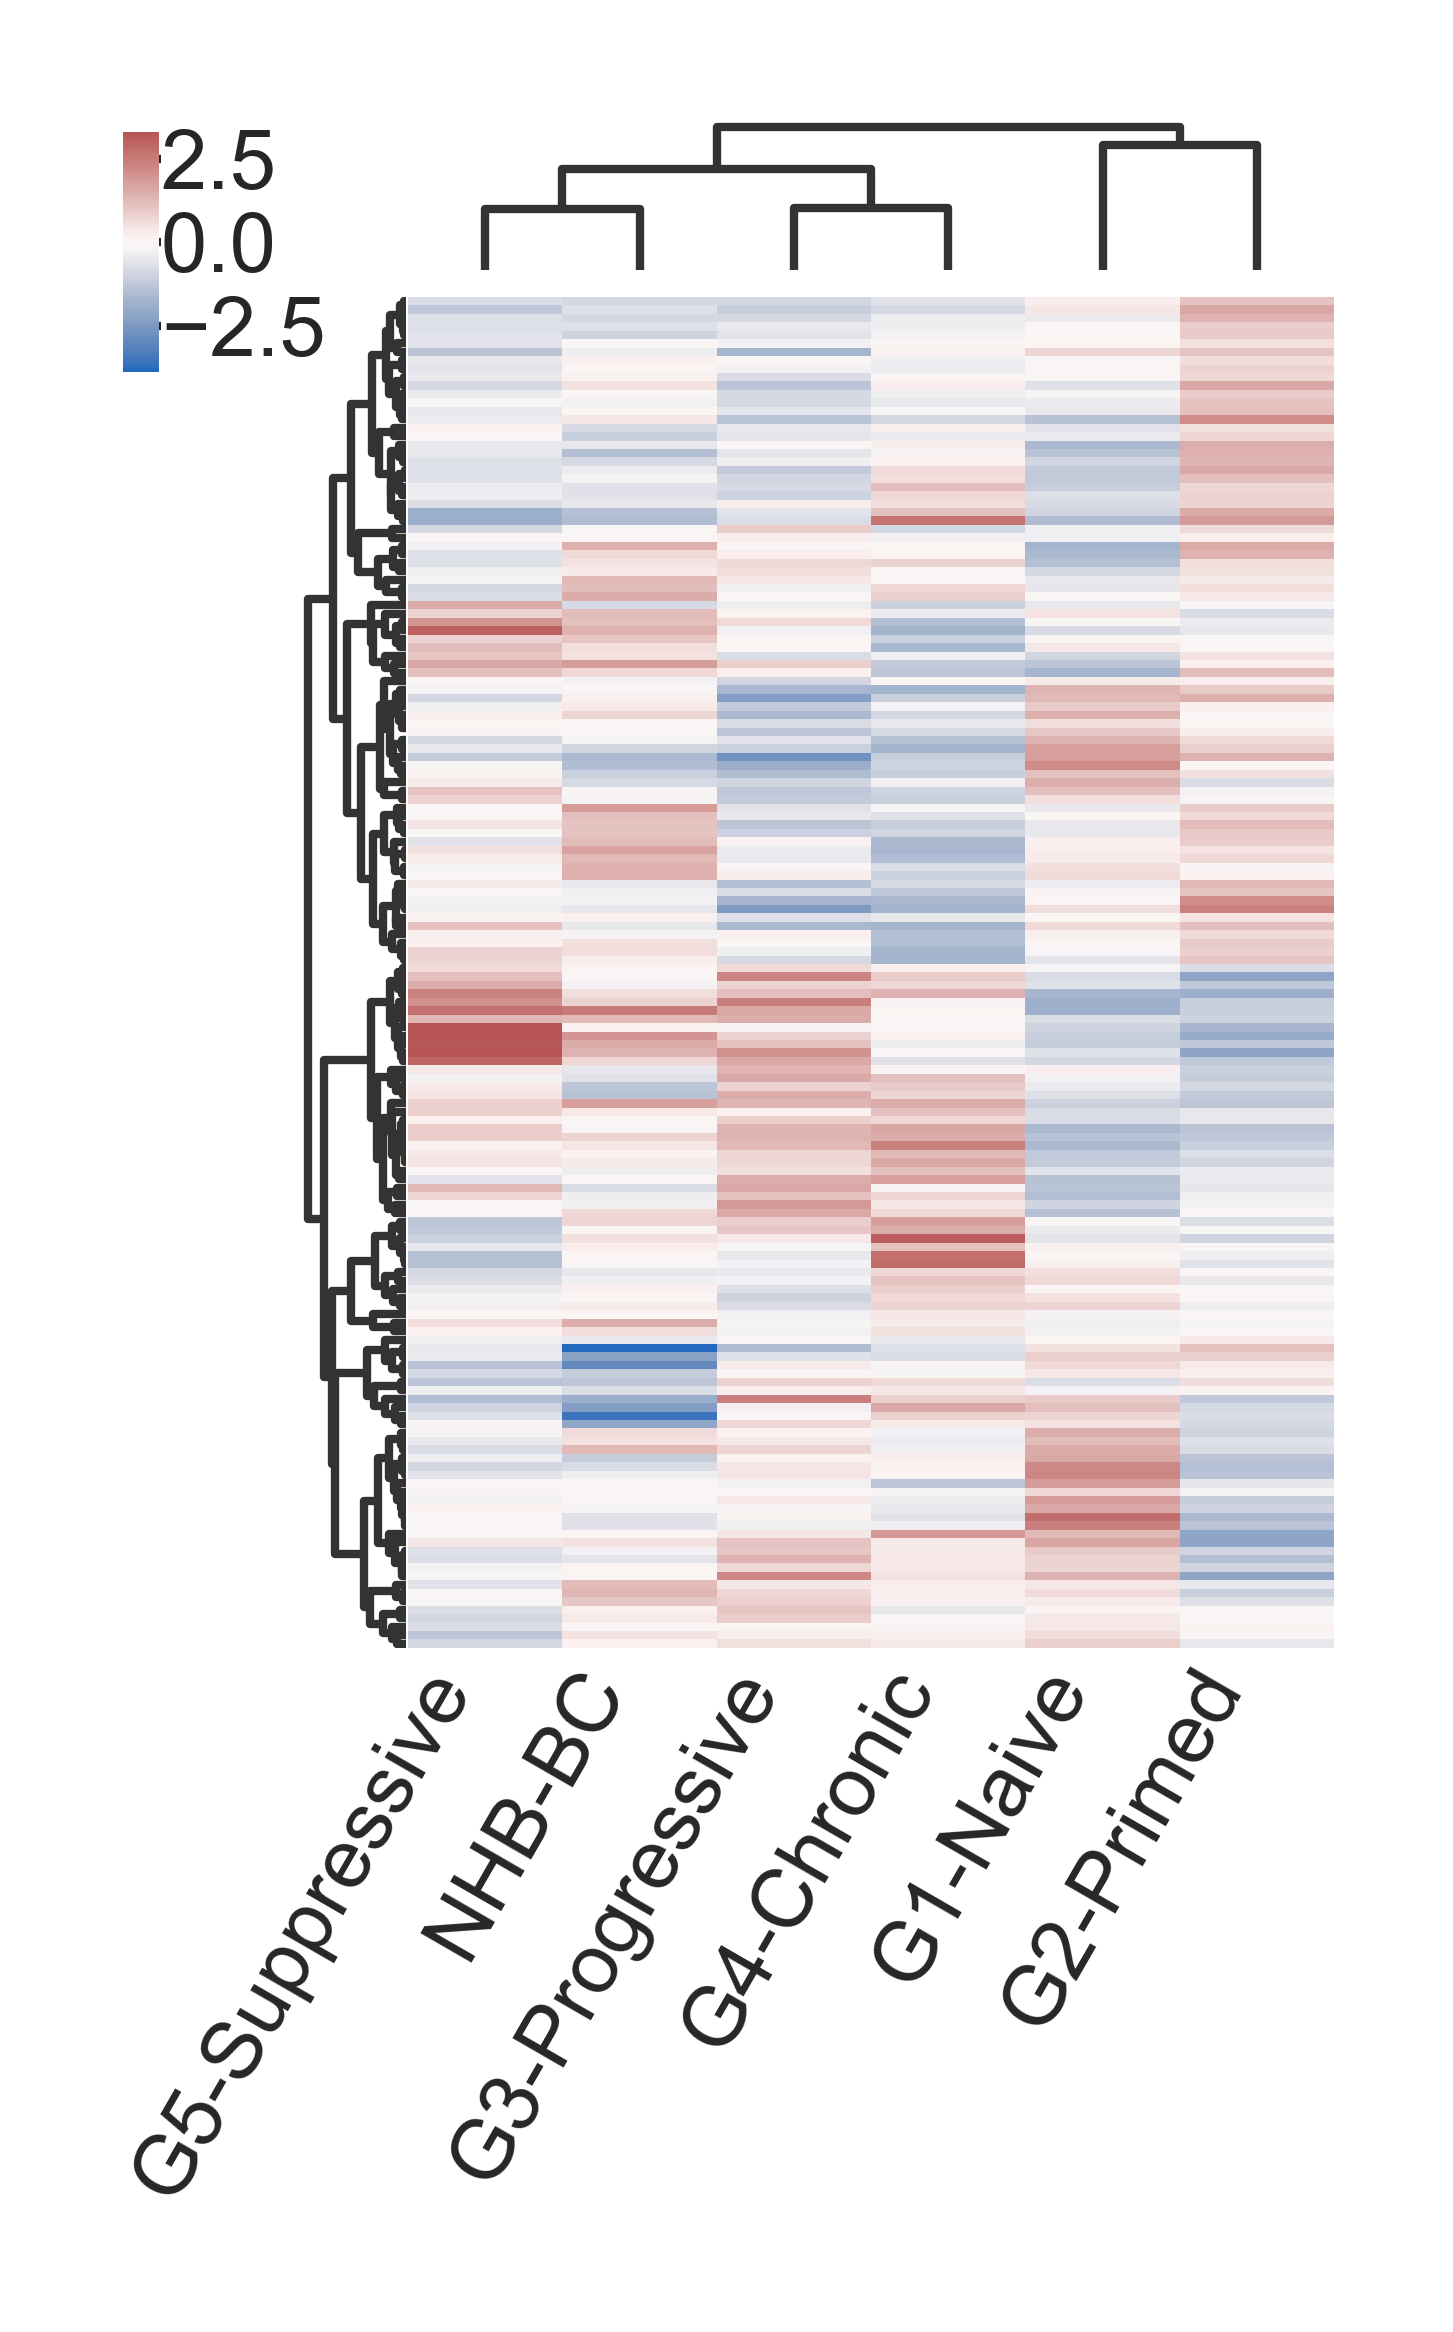

In [59]:
from scipy.stats import zscore
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# === 1. Prepare data ===
cols_sel = [
    'G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
    'NHB-BC'#,'NHB-BC Up Protein'
]

mat = mg[cols_sel].apply(pd.to_numeric, errors='coerce')

# Z-score columns
mat_scaled = pd.DataFrame(
    zscore(mat.values, axis=0, nan_policy='omit'),
    index=mat.index,
    columns=mat.columns
)

# === 2. Custom x-axis labels ===
xtick_map = {
    'G1_signature': 'G1-Naive',
    'G2_signature': 'G2-Primed',
    'G3_signature': 'G3-Progressive',
    'G4_signature': 'G4-Chronic',
    'G5_signature': 'G5-Suppressive',
    'NHB-BC Up': 'NHB-BC Up'#,
    #'NHB-BC Up Protein': 'NHB-BC Up Protein'
}
mat_scaled.columns = [xtick_map.get(c, c) for c in mat_scaled.columns]

# === 3. Plot clustermap ===
g = sns.clustermap(
    mat_scaled,
    metric='correlation',
    method='average',
    cmap='vlag', center=0,
    figsize=(1.5, 2),
    dendrogram_ratio=.1,
    cbar_pos=(-.04, .85, 0.02, 0.1)  # (x, y, width, height) — lower left, thinner, shorter
)

# Remove y-axis tick labels
g.ax_heatmap.set_yticklabels([])

# Rotate x-axis labels for clarity
g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(),
    rotation=60, ha='right', fontsize=5
)

g.ax_heatmap.tick_params(axis='y', length=0)
g.ax_heatmap.tick_params(axis='x', pad=-3)
g.ax_cbar.tick_params(
    axis='y',      # because the colorbar is vertical
    length=0.1,    # tick length (in points)
    labelsize=5    # font size of tick labels
)

# plt.savefig('plots/F8/160pt_heatmap.svg', bbox_inches='tight')

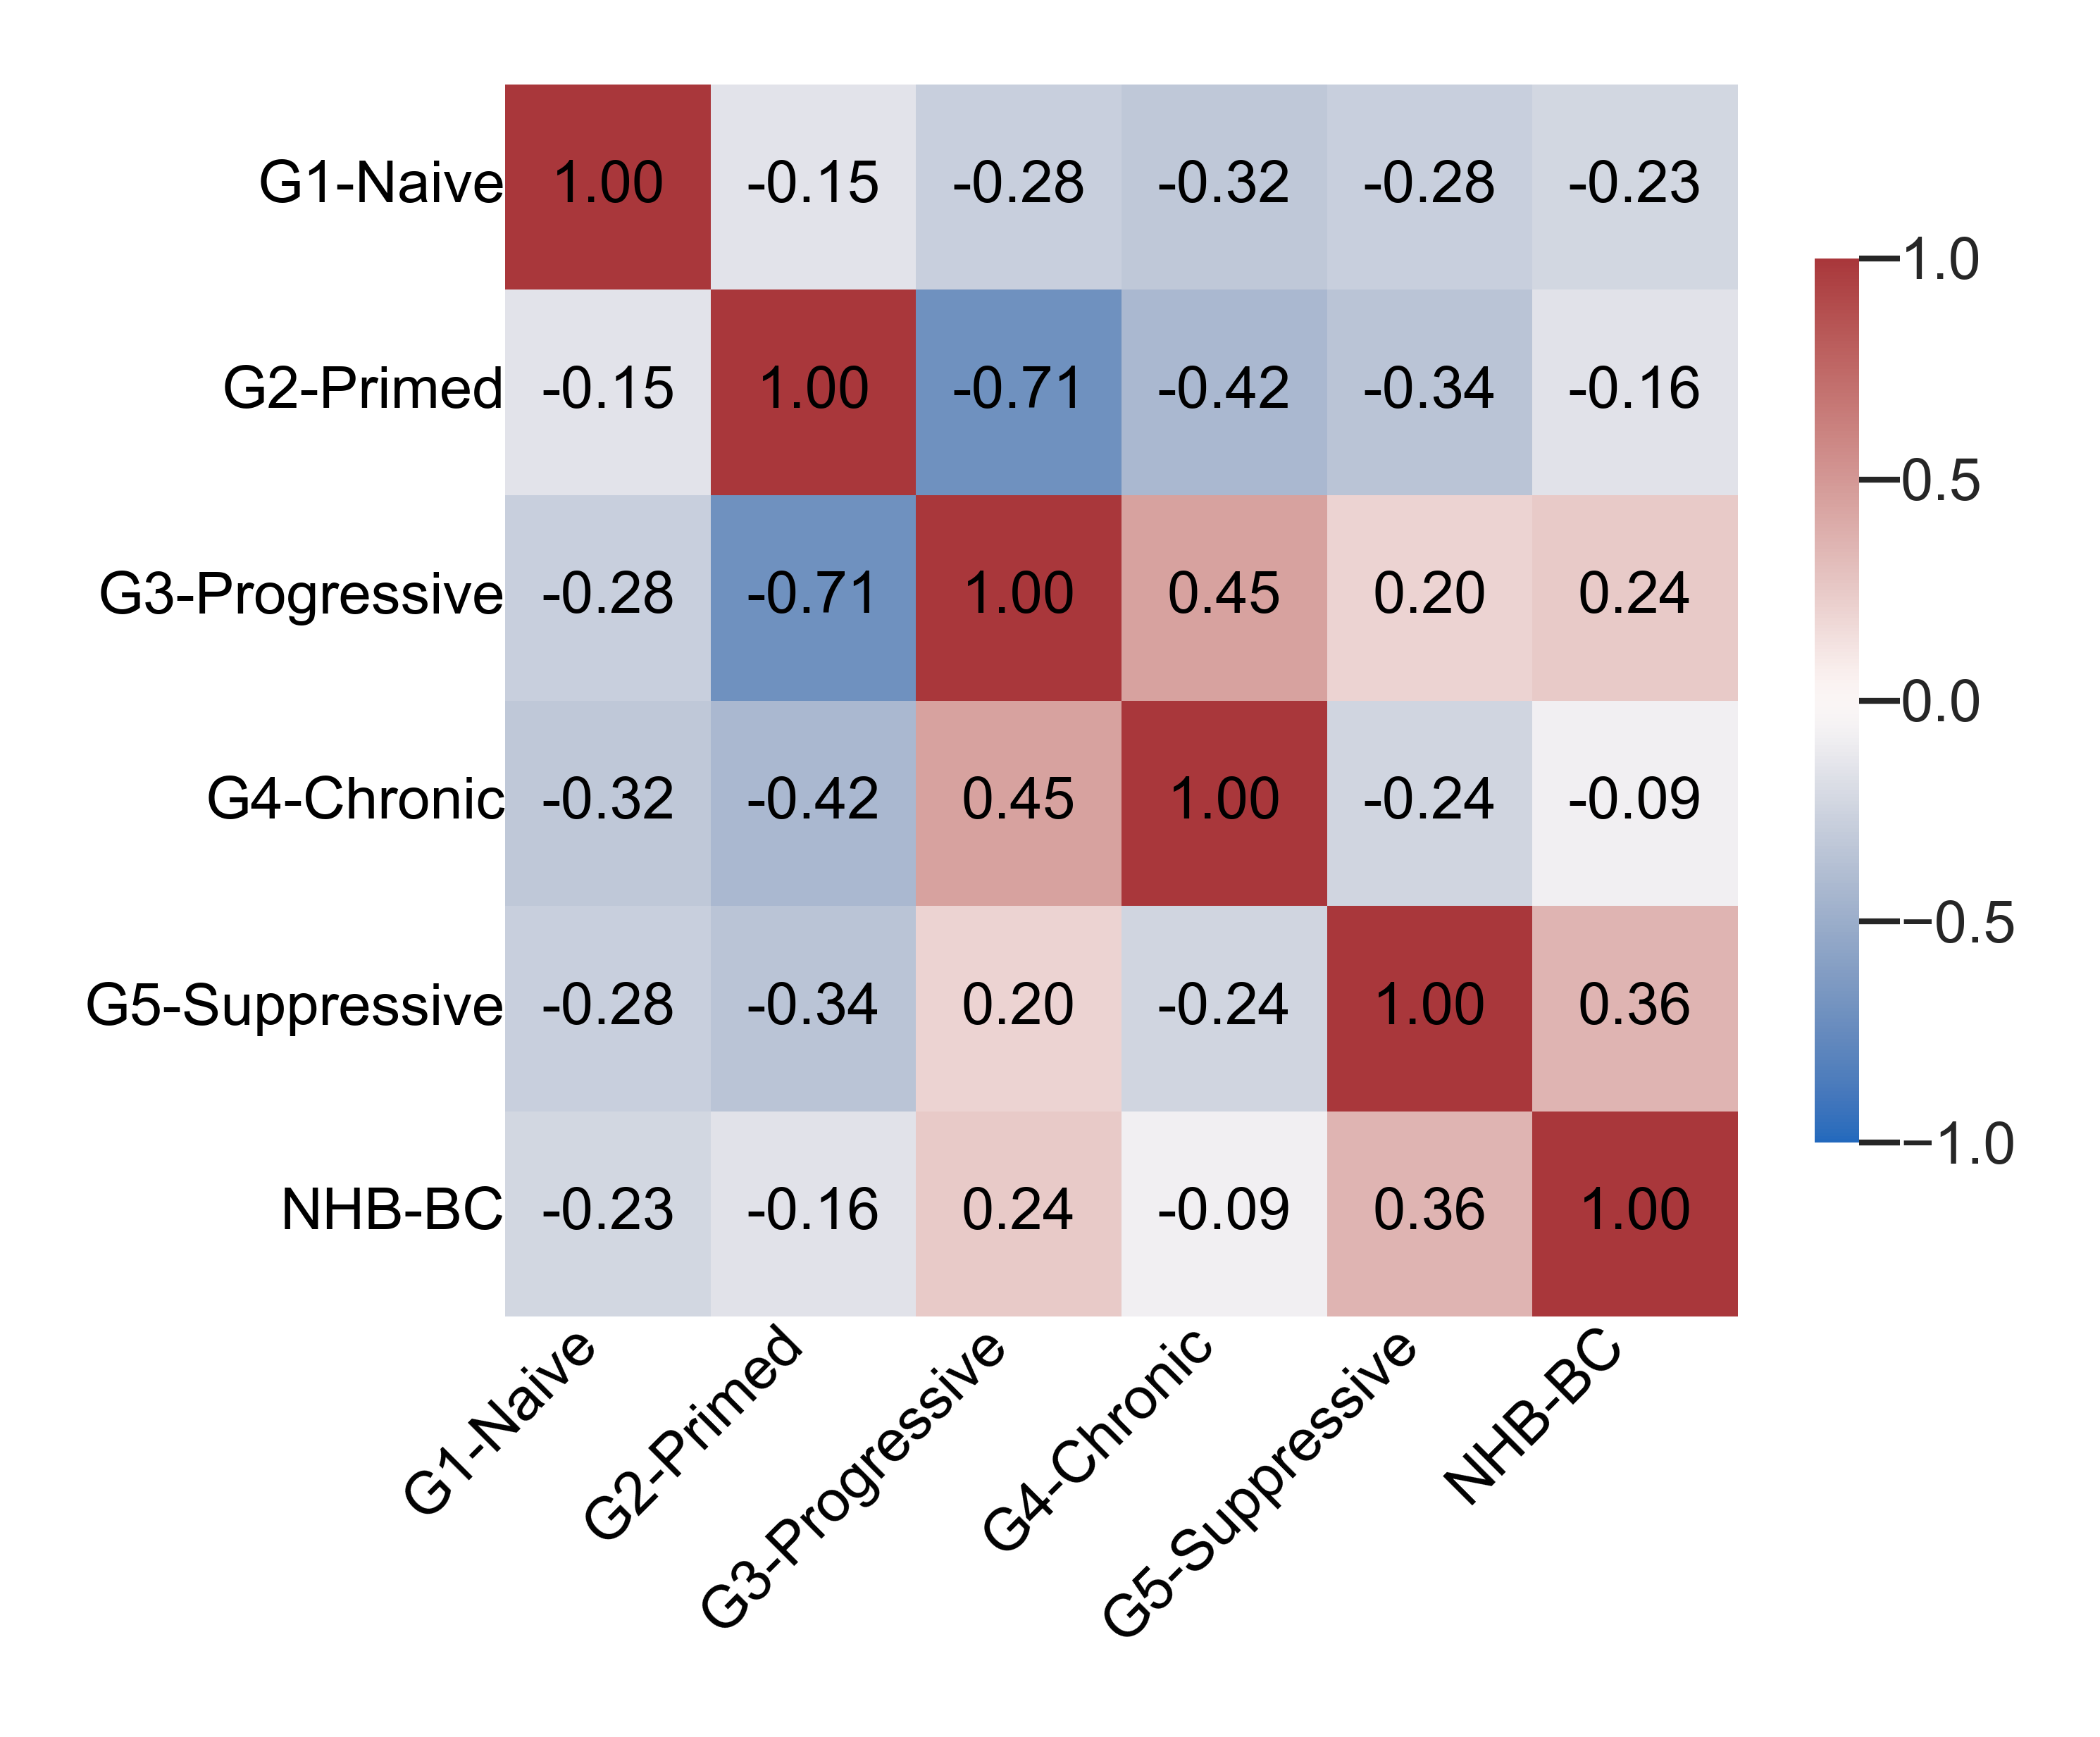

In [60]:
cor_mat = mat_scaled.corr(method='spearman')

# Mask the lower triangle (show upper only)
mask = np.tril(np.ones_like(cor_mat, dtype=bool), k=-1)

plt.figure(figsize=(2.5, 2.5))
ax = sns.heatmap(
    cor_mat,
    mask=None,
    cmap='vlag',      # reversed: blue=high, red=low/negative
    vmin=-1, vmax=1,
    annot=True,         # add coefficients
    fmt=".2f",
    annot_kws={"color": "black", "fontsize": 5},
    square=True,
    cbar_kws={"shrink": 0.5}
)

# Ticks in black (like tl.col='black')
ax.tick_params(colors='black', labelsize=5, length=0, pad=0)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)


plt.tight_layout()
plt.savefig('plots/F8/160pt_corrmap.svg', bbox_inches='tight')

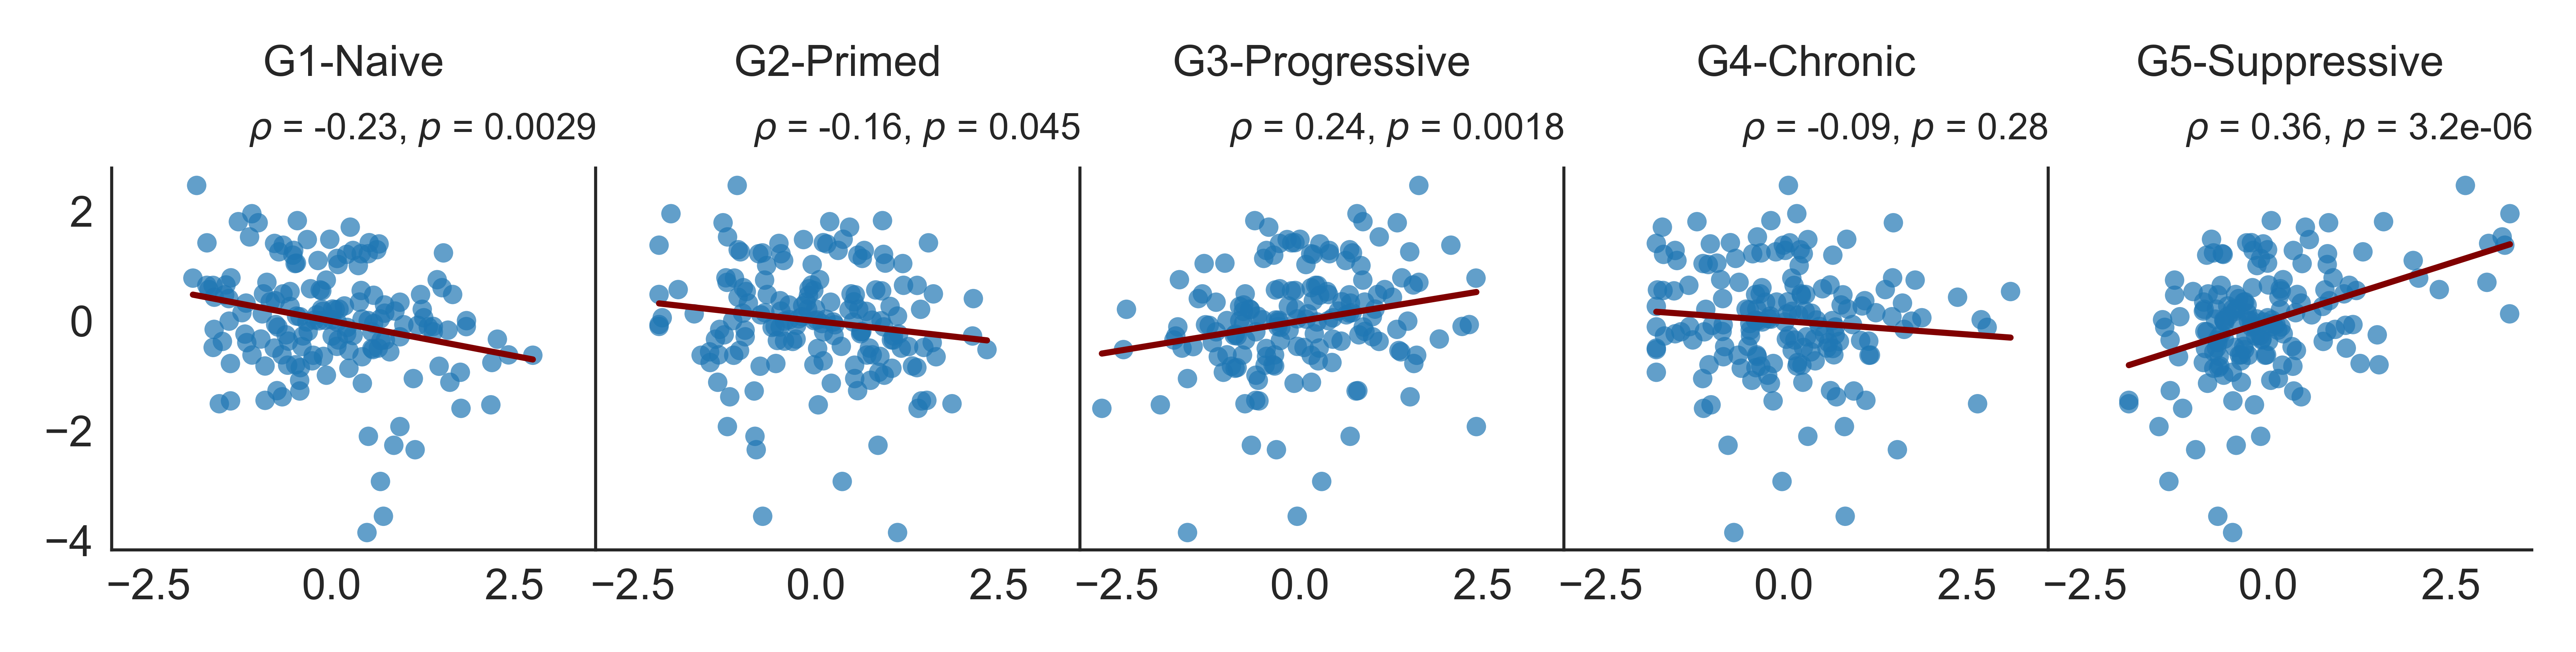

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import spearmanr

sns.set_style("white")

sig_map = {
    'G1_signature': 'G1-Naive',
    'G2_signature': 'G2-Primed',
    'G3_signature': 'G3-Progressive',
    'G4_signature': 'G4-Chronic',
    'G5_signature': 'G5-Suppressive'
}
score_names = list(sig_map.values())

# Prepare long format
df_scores = (
    mat_scaled.reset_index(drop=True)[score_names]
    .rename(columns=sig_map)
    .assign(idx=lambda d: d.index)
    .melt(id_vars='idx', var_name='Signature', value_name='Score')
)

df_outcomes = (
    mat_scaled.reset_index(drop=True)[['NHB-BC']]
    .assign(idx=lambda d: d.index)
    .melt(id_vars='idx', var_name='OutcomeName', value_name='OutcomeValue')
)

df_long = df_scores.merge(df_outcomes, on='idx').drop(columns='idx')

# Function to map scatter + regression + annotation
def facet_scatter(data, color, **kws):
    ax = plt.gca()
    ax.scatter(data["Score"], data["OutcomeValue"], s=10, alpha=0.7, edgecolor="none")
    sns.regplot(
        data=data, x="Score", y="OutcomeValue",
        scatter=False, ci=None, ax=ax, color='maroon', line_kws={"lw": 1.0}
    )
    x = data["Score"].to_numpy()
    y = data["OutcomeValue"].to_numpy()
    if np.nanstd(x) > 0 and np.nanstd(y) > 0:
        r, p = spearmanr(x, y, nan_policy='omit')
        txt = f"$\\rho$ = {r:.2f}, $p$ = {p:.2g}"
    else:
        txt = r"$\rho$ = NA\n$p$ = NA"

    ax.text(
        1, 1.1, txt,          # middle-right
        transform=ax.transAxes,
        ha="right", va="center",
        fontsize=6
    )
    
# Split by OutcomeName and plot/save each row
for outcome_name in df_long["OutcomeName"].unique():
    df_row = df_long[df_long["OutcomeName"] == outcome_name]

    g = sns.FacetGrid(
        df_row,
        col="Signature",
        sharex=True, sharey=True,
        height=1, aspect=1.0
    )
    g.map_dataframe(facet_scatter)

    # Make panels square
    for ax, sig in zip(g.axes.flat, score_names):
        ax.set_ylabel('', fontsize=7)
        ax.set_title(sig, fontsize=7, pad=15)
        ax.set_xlabel('', fontsize=6)
        ax.tick_params(labelsize=7, length=2, pad=1)

    
    # Save as SVG
    fname = f"plots/F8/160pt_scatter_{outcome_name.replace(' ', '_')}.svg"
    g.fig.set_size_inches(6, 2)

    g.fig.subplots_adjust(wspace=0.0005, hspace=0.02)
    
    g.savefig(fname, bbox_inches='tight')
    plt.show()